<a href="https://colab.research.google.com/github/adeliavee/Credit-Default-Prediction-UTS-PMML/blob/main/Adelia_UTS_PMML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **UTS PMML**

**Nama: Adelia Venie Diniar**

NIM: 2404220014


### **Experiment 0**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!pip install -q kagglehub[pandas-datasets]

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [ ]:
file_path = "UCI_Credit_Card.csv"
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "uciml/default-of-credit-card-clients-dataset",
    file_path
)
print("First 5 records:", df.head())

/tmp/ipykernel_1822/3238673423.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 0.98M/0.98M [00:00<00:00, 15.4MB/s]

Extracting zip of UCI_Credit_Card.csv...


First 5 records:    ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1    20000.0    2          2         1   24      2      2     -1     -1   
1   2   120000.0    2          2         2   26     -1      2      0      0   
2   3    90000.0    2          2         2   34      0      0      0      0   
3   4    50000.0    2          2         1   37      0      0      0      0   
4   5    50000.0    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...        0.0        0.0        0.0       0.0     689.0       0.0   
1  ...     3272.0     3455.0     3261.0       0.0    1000.0    1000.0   
2  ...    14331.0    14948.0    15549.0    1518.0    1500.0    1000.0   
3  ...    28314.0    28959.0    29547.0    2000.0    2019.0    1200.0   
4  ...    20940.0    19146.0    19131.0    2000.0   36681.0   10000.0   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default.payment.next.month  
0      

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
print("Missing value per kolom:")
print(df.isnull().sum())

Missing value per kolom:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64


Tidak terdapat Missing value pada data ini.

In [ ]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


Tidak terdapat data duplikat.

In [ ]:
display(df.describe())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


### Cek nilai tidak wajar

In [ ]:
print(df["SEX"].value_counts(), "\n")
print(df["EDUCATION"].value_counts(), "\n")
print(df["MARRIAGE"].value_counts(), "\n")

SEX
2    18112
1    11888
Name: count, dtype: int64 

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64 

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64 



Terdapat nilaii 0 pada data EDUCATION dan MARRIAGE namun  pada deskripsi data yang di berikan nilai 0 tidak tercantum sehingga menunjukkan nilai yang tidak sesuai atau tidak wajar.

### Mengubah data yang tidak sesuai

In [ ]:
df["EDUCATION"] = df["EDUCATION"].replace({
    0: 4
})

print(df["EDUCATION"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      137
5      280
6       51
Name: count, dtype: int64


In [ ]:
df["MARRIAGE"] = df["MARRIAGE"].replace({
    0: 3
})
print(df["MARRIAGE"].value_counts().sort_index())

MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


Sudah tidak terdapat nilaii 0 pada data EDUCATION dan MARRIAGE.

### Distribusi target

In [ ]:
target = "default.payment.next.month"

print("\nJumlah masing-masing kelas target:")
print(df[target].value_counts().sort_index())

print("\nPersentase masing-masing kelas target:")
print(df[target].value_counts(normalize=True)* 100)


Jumlah masing-masing kelas target:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Persentase masing-masing kelas target:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


Sebanyak 77,88% nasabah tidak mengalami default, sedangkan 22,12% mengalami default. Artinya, kelas target tidak seimbang.

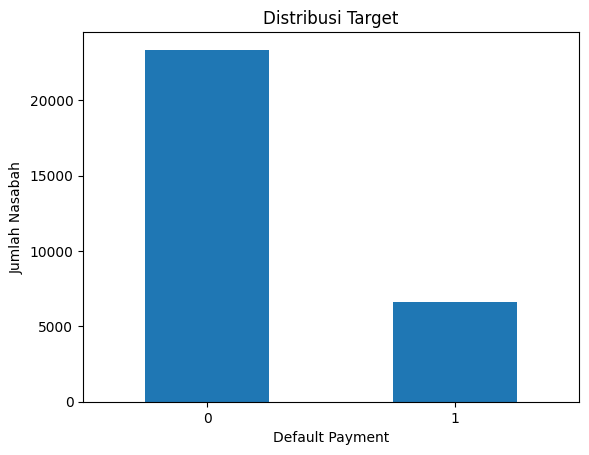

In [ ]:
df[target].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Default Payment")
plt.ylabel("Jumlah Nasabah")
plt.title("Distribusi Target")
plt.xticks(rotation=0)
plt.show()

### Melakukan train-test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["ID", target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
print("Ukuran data:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Ukuran data:
X_train: (24000, 23)
X_test : (6000, 23)
y_train: (24000,)
y_test : (6000,)


Data dibagi menjadi 24.000 data training dan 6.000 data testing dengan proporsi kelas target yang tetap sama.

In [ ]:
print("Proporsi target data training:")
print(y_train.value_counts(normalize=True) * 100)

print("\nProporsi target data testing:")
print(y_test.value_counts(normalize=True) * 100)

Proporsi target data training:
default.payment.next.month
0    77.879167
1    22.120833
Name: proportion, dtype: float64

Proporsi target data testing:
default.payment.next.month
0    77.883333
1    22.116667
Name: proportion, dtype: float64


**Experiment 1**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
model_lr = LogisticRegression(
    max_iter=5000,
    random_state=42
)
model_lr.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=5000, random_state=42)

In [ ]:
cv_f1 = cross_val_score(
    model_lr,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1-score setiap fold:")
print(cv_f1)

print("\nRata-rata CV F1-score:", cv_f1.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

F1-score setiap fold:
[0.33872101 0.39000694 0.36287509 0.38069341 0.37196391]

Rata-rata CV F1-score: 0.36885207171928996


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Terdapat ConvergenceWarning dari Logistic Regression, yang artinya modelnya masih menghasilkan nilai F1, tetapi proses optimasinya belum benar-benar mencapai kondisi konvergen. Ini bisa diakibatkan karena terdapat variabel dengan skala yang sangat berbeda.

In [ ]:
cv_result = pd.DataFrame({
    'Fold': range(1, 6),
    'F1-score': cv_f1
})

cv_result.loc[len(cv_result)] = ['Mean', cv_f1.mean()]
cv_result

,Fold,F1-score
0,1,0.338721
1,2,0.390007
2,3,0.362875
3,4,0.380693
4,5,0.371964
5,Mean,0.368852


Hasil 5-fold cross-validation menunjukkan nilai F1-score rata-rata sebesar 0,368852. Nilai F1-score antar-fold berada pada rentang 0,3387–0,3900, sehingga performa model relatif tidak terlalu jauh berbeda pada setiap pembagian data. Namun, nilai F1-score yang masih rendah menunjukkan bahwa kemampuan Logistic Regression baseline dalam mendeteksi kelas default masih belum optimal. Terdaapat ConvergenceWarning  yang membuktikan bahwa proses optimasi parameter Logistic Regression pada data baseline belum sepenuhnya selesai.

In [67]:
y_pred_lr = model_lr.predict(X_test)

In [66]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)


print("Hasil Experiment 1")
print("CV F1-score :", cv_f1.mean())
print("Accuracy    :", accuracy_lr)
print("Precision   :", precision_lr)
print("Recall      :", recall_lr)
print("F1-score    :", f1_lr)

Hasil Experiment 1
CV F1-score : 0.36885207171928996
Accuracy    : 0.808
Precision   : 0.6857749469214437
Recall      : 0.24340617935192163
F1-score    : 0.3592880978865406


Nilai accuracy menunjukkan bahwa model mampu memberikan prediksi yang benar terhadap sekitar 80,8% data testing. Namun, accuracy saja belum cukup untuk menggambarkan kemampuan model karena target memiliki distribusi kelas yang tidak seimbang.

Nilai precision sebesar 68,8% menunjukkan model cukup baik dalam menghasilkan prediksi default yang tepat.

Nilai recall hanya sebesar 24,3%, yang menunjukkan bahwa masih banyak kasus default yang tidak berhasil dikenali oleh model.

F1-score pada data testing sebesar 0,3593. Nilai ini menunjukkan bahwa keseimbangan antara precision dan recall masih kurang baik. Akibat recall yang rendah membuat F1-score menjadi rendah. Kondisi ini sejalan dengan hasil cross-validation yang juga hanya menghasilkan rata-rata F1-score sebesar 0,3689.

**Experiment 2**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
model_lr_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
cv_f1_scaled = cross_val_score(
    model_lr_scaled,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1-score setiap fold:")
print(cv_f1_scaled)

print("\nRata-rata CV F1-score:",
      cv_f1_scaled.mean())

F1-score setiap fold:
[0.35783634 0.37826394 0.37535014 0.36161335 0.35684062]

Rata-rata CV F1-score: 0.36598087776836846


In [ ]:
cv_result = pd.DataFrame({
    'Fold': range(1, 6),
    'F1-score': cv_f1_scaled
})

cv_result.loc[len(cv_result)] = ['Mean', cv_f1_scaled.mean()]
cv_result

,Fold,F1-score
0,1,0.357836
1,2,0.378264
2,3,0.375350
3,4,0.361613
4,5,0.356841
5,Mean,0.365981


In [ ]:
model_lr_scaled.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred_lr_scaled = model_lr_scaled.predict(X_test)

In [ ]:
accuracy_lr_scaled = accuracy_score(
    y_test,
    y_pred_lr_scaled
)

precision_lr_scaled = precision_score(
    y_test,
    y_pred_lr_scaled
)

recall_lr_scaled = recall_score(
    y_test,
    y_pred_lr_scaled
)

f1_lr_scaled = f1_score(
    y_test,
    y_pred_lr_scaled
)


print("Hasil Experiment 2")
print("CV F1-score :", cv_f1_scaled.mean())
print("Accuracy    :", accuracy_lr_scaled)
print("Precision   :", precision_lr_scaled)
print("Recall      :", recall_lr_scaled)
print("F1-score    :", f1_lr_scaled)

Hasil Experiment 2
CV F1-score : 0.36598087776836846
Accuracy    : 0.808
Precision   : 0.6865671641791045
Recall      : 0.2426525998492841
F1-score    : 0.3585746102449889


In [ ]:
hasil_perbandingan = pd.DataFrame({
    "Model": ["Logistic Regression Baseline", "Logistic Regression + Scaling"],
    "CV F1-Score": [cv_f1.mean(), cv_f1_scaled.mean()],
    "Accuracy": [accuracy_lr, accuracy_lr_scaled],
    "Precision": [precision_lr, precision_lr_scaled],
    "Recall": [recall_lr, recall_lr_scaled],
    "F1-Score": [f1_lr, f1_lr_scaled]
})

hasil_perbandingan

,Model,CV F1-Score,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression Baseline,0.368852,0.808,0.685775,0.243406,0.359288
1,Logistic Regression + Scaling,0.365981,0.808,0.686567,0.242653,0.358575


Hasil Experiment 2 menunjukkan bahwa penerapan StandardScaler belum meningkatkan performa Logistic Regression berdasarkan F1-score. Nilai CV F1-score menurun dari 0,368852 pada baseline menjadi 0,365981, sedangkan F1-score pada juga sedikit menurun dari 0,359288 menjadi 0,358575. Nilai recall menurun tipis dari 24,34% menjadi 24,27%, sementara precision meningkat dari 68,58% menjadi 68,66%. Perubahan tersebut tidak menghasilkan peningkatan F1-score. Dengan demikian, penerapan StandardScaler pada eksperimen ini belum meningkatkan performa Logistic Regression berdasarkan F1-score.

### **Experiment 3**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model_tree = DecisionTreeClassifier(
    random_state=42
)

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [ ]:
models = {
    "Logistic Regression": model_logistic,
    "Decision Tree": model_tree,
    "Random Forest": model_rf
}

In [ ]:
results_exp3 = []

for name, model in models.items():

    # 5-fold CV
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    # Training
    model.fit(X_train, y_train)

    # Prediksi
    y_pred = model.predict(X_test)

    # Evaluasi
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results_exp3.append({
        "Model": name,
        "CV F1": cv_scores.mean(),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

In [ ]:
results_exp3 = pd.DataFrame(results_exp3)

display(results_exp3)

,Model,CV F1,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.365981,0.808000,0.686567,0.242653,0.358575
1,Decision Tree,0.404524,0.716667,0.370396,0.401658,0.385394
2,Random Forest,0.471028,0.812833,0.634565,0.362472,0.461391


Random Forest memberikan CV F1-score tertinggi sebesar 0,4710 yang diikuti Decision Tree dengan CV F1-score sebesar 0.4045 dan Logistic Regression memiliki kemampuan presiksi yang paling rendah dengan CV F1-score sebesar 0.3660.

### **Experiment 4**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(
    random_state=42
)

In [ ]:
parameter = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"],
    "min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    rf,
    parameter,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'class_weight': [None, 'balanced'],
                         'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100]},
             scoring='f1')

In [55]:
print("Parameter terbaik:")
print(grid_rf.best_params_)

print("\nBest CV F1-Score:")
print(grid_rf.best_score_)

Parameter terbaik:
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}

Best CV F1-Score:
0.5444199899953107


In [56]:
rf_tuning = grid_rf.best_estimator_

y_pred_rf_tuning = rf_tuning.predict(X_test)

In [57]:
accuracy_rf_tuning = accuracy_score(y_test, y_pred_rf_tuning)
precision_rf_tuning = precision_score(y_test, y_pred_rf_tuning)
recall_rf_tuning = recall_score(y_test, y_pred_rf_tuning)
f1_rf_tuning = f1_score(y_test, y_pred_rf_tuning)

print("Random Forest setelah GridSearchCV")
print("CV F1-Score :", grid_rf.best_score_)
print("Accuracy    :", accuracy_rf_tuning)
print("Precision   :", precision_rf_tuning)
print("Recall      :", recall_rf_tuning)
print("F1-Score    :", f1_rf_tuning)

Random Forest setelah GridSearchCV
CV F1-Score : 0.5444199899953107
Accuracy    : 0.7886666666666666
Precision   : 0.5204152249134948
Recall      : 0.5666917859834213
F1-Score    : 0.5425685425685426


In [58]:
# Extract Random Forest metrics from results_exp3
rf_results = results_exp3[results_exp3["Model"] == "Random Forest"].iloc[0]

hasil_exp4 = pd.DataFrame({
    "Model": [
        "Random Forest sebelum tuning",
        "Random Forest setelah tuning"
    ],

    "CV F1-Score": [
        rf_results["CV F1"],
        grid_rf.best_score_
    ],

    "Accuracy": [
        rf_results["Accuracy"],
        accuracy_rf_tuning
    ],

    "Precision": [
        rf_results["Precision"],
        precision_rf_tuning
    ],

    "Recall": [
        rf_results["Recall"],
        recall_rf_tuning
    ],

    "F1-Score": [
        rf_results["F1"],
        f1_rf_tuning
    ]
})

hasil_exp4.round(4)

,Model,CV F1-Score,Accuracy,Precision,Recall,F1-Score
0,Random Forest sebelum tuning,0.4710,0.8128,0.6346,0.3625,0.4614
1,Random Forest setelah tuning,0.5444,0.7887,0.5204,0.5667,0.5426


CV F1-score Random Forest setelah tuning meningkat menjadi 0,5444, menunjukkan tuning berhasil meningkatkan kemampuan model dalam mendeteksi kelas default. Namun, Accuracy dan Precision mengalami penurunan dibandingkan sebelum tuning.Tetapi, Recall  mengalami peningkatan dari 0,3625 menjadi 56,67%, sehingga model jauh lebih baik dalam menemukan nasabah yang mengalami default dan F1-score juga meningkat menjadi 0,5426, sehingga Random Forest setelah tuning memberikan performa yang lebih baik secara keseluruhan.

### **Experiment 5**

In [59]:
from sklearn.ensemble import GradientBoostingClassifier

In [60]:
gb = GradientBoostingClassifier(
    random_state=2020
)

In [61]:
cv_gb = cross_val_score(
    gb,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1-Score setiap fold:")
print(cv_gb)

print("Rata-rata CV F1-Score:")
print(cv_gb.mean())

F1-Score setiap fold:
[0.48067633 0.48834356 0.46711739 0.48886213 0.46505875]
Rata-rata CV F1-Score:
0.47801163255610846


In [62]:
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=2020)

In [63]:
y_pred_gb = gb.predict(X_test)

In [64]:
accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("CV F1-Score :", cv_gb.mean())
print("Accuracy    :", accuracy_gb)
print("Precision   :", precision_gb)
print("Recall      :", recall_gb)
print("F1-Score    :", f1_gb)

Gradient Boosting
CV F1-Score : 0.47801163255610846
Accuracy    : 0.8186666666666667
Precision   : 0.6662030598052852
Recall      : 0.36096458176337604
F1-Score    : 0.4682306940371456


In [65]:
hasil_exp5 = pd.DataFrame({
    "Model": [
        "Random Forest setelah tuning",
        "Gradient Boosting"
    ],

    "CV F1-Score": [
        grid_rf.best_score_,
        cv_gb.mean()
    ],

    "Accuracy": [
        accuracy_rf_tuning,
        accuracy_gb
    ],

    "Precision": [
        precision_rf_tuning,
        precision_gb
    ],

    "Recall": [
        recall_rf_tuning,
        recall_gb
    ],

    "F1-Score": [
        f1_rf_tuning,
        f1_gb
    ]
})

hasil_exp5.round(4)

,Model,CV F1-Score,Accuracy,Precision,Recall,F1-Score
0,Random Forest setelah tuning,0.5444,0.7887,0.5204,0.5667,0.5426
1,Gradient Boosting,0.4780,0.8187,0.6662,0.3610,0.4682


Rata-rata CV F1-score sebesar 0,4780, menunjukkan performanya cukup baik tetapi masih di bawah Random Forest setelah tuning. Accuracy menunjukan 81,87%, menjadi accuracy tertinggi dibandingkan Random Forest setelah tuning. Precision meninggat menjadi 66,62%, artinya prediksi default yang dihasilkan cukup tepat. Namun, Recall menurun menjadi 36,10%, sehingga masih terdapat cukup banyak kasus default yang tidak terdeteksi. F1-score juga menurun menjadi 0,4682, lebih rendah daripada Random Forest setelah tuning.

In [68]:
from sklearn.ensemble import AdaBoostClassifier

In [73]:
ada = AdaBoostClassifier(
    random_state=42
)

In [74]:
cv_ada = cross_val_score(
    ada,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1-Score setiap fold:")
print(cv_ada)

print("Rata-rata CV F1-Score:")
print(cv_ada.mean())

F1-Score setiap fold:
[0.45692884 0.45273312 0.44783715 0.45408805 0.42255347]
Rata-rata CV F1-Score:
0.44682812512712256


In [75]:
ada.fit(X_train, y_train)

AdaBoostClassifier(random_state=42)

In [76]:
y_pred_ada = ada.predict(X_test)

In [78]:
accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada)
recall_ada = recall_score(y_test, y_pred_ada)
f1_ada = f1_score(y_test, y_pred_ada)

print("AdaBoost")
print("CV F1-Score :", cv_ada.mean())
print("Accuracy    :", accuracy_ada)
print("Precision   :", precision_ada)
print("Recall      :", recall_ada)
print("F1-Score    :", f1_ada)

AdaBoost
CV F1-Score : 0.44682812512712256
Accuracy    : 0.8165
Precision   : 0.6722560975609756
Recall      : 0.33232856066315
F1-Score    : 0.44478063540090773


In [79]:
hasil_exp5 = pd.DataFrame({
    "Model": [
        "Random Forest setelah tuning",
        "Gradient Boosting",
        "AdaBoost"
    ],

    "CV F1-Score": [
        grid_rf.best_score_,
        cv_gb.mean(),
        cv_ada.mean()
    ],

    "Accuracy": [
        accuracy_rf_tuning,
        accuracy_gb,
        accuracy_ada
    ],

    "Precision": [
        precision_rf_tuning,
        precision_gb,
        precision_ada
    ],

    "Recall": [
        recall_rf_tuning,
        recall_gb,
        recall_ada
    ],

    "F1-Score": [
        f1_rf_tuning,
        f1_gb,
        f1_ada
    ]
})

hasil_exp5.round(4)

,Model,CV F1-Score,Accuracy,Precision,Recall,F1-Score
0,Random Forest setelah tuning,0.5444,0.7887,0.5204,0.5667,0.5426
1,Gradient Boosting,0.4780,0.8187,0.6662,0.3610,0.4682
2,AdaBoost,0.4468,0.8165,0.6723,0.3323,0.4448


AdaBoost memperoleh CV F1-Score sebesar 0,4468, yang merupakan nilai terendah dari ketiga model. Model memperoleh accuracy 0,8165, precision 0,6723, recall 0,3323, dan F1-score 0,4448.

AdaBoost memiliki accuracy dan precision yang cukup tinggi, tetapi recall hanya 33,23%. Artinya, kemampuan model dalam menemukan nasabah yang mengalami default masih rendah. Hal tersebut menyebabkan F1-score AdaBoost menjadi yang paling rendah dibandingkan kedua model lainnya.
